<a href="https://colab.research.google.com/github/sridewisnn/GEN_AI/blob/main/cGAN_Dataset_Classifier_Generate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
   from google.colab import drive
   drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


fatal: destination path 'GEN_AI' already exists and is not an empty directory.
Python      : 3.13.18
PyTorch     : 2.11.0+cpu
Torchvision : 0.26.0+cpu
Device: cpu
PERINGATAN: berjalan di CPU. Aktifkan GPU lewat Runtime > Change runtime type > T4 GPU.
{
  "seed": 42,
  "data_dir": "./data",
  "img_size": 28,
  "img_channels": 1,
  "num_classes": 10,
  "norm_mean": 0.5,
  "norm_std": 0.5,
  "batch_size": 128,
  "num_workers": 2,
  "train_size": 60000,
  "z_dim": 100,
  "g_embed_dim": 50,
  "g_channels": [
    128,
    64,
    32
  ],
  "d_channels": [
    64,
    128,
    256
  ],
  "leaky_slope": 0.2,
  "init_std": 0.02,
  "d_dropout": 0.0,
  "d_spectral_norm": false,
  "epochs": 50,
  "lr_g": 0.0002,
  "lr_d": 0.0002,
  "beta1": 0.5,
  "beta2": 0.999,
  "weight_decay": 0.0,
  "d_steps": 1,
  "g_steps": 1,
  "real_target": 0.9,
  "fake_target": 0.0,
  "g_target": 1.0,
  "sample_every": 5,
  "ckpt_every": 10,
  "n_per_class_grid": 10,
  "eval_per_class": 1000,
  "use_drive": true,
  "dri

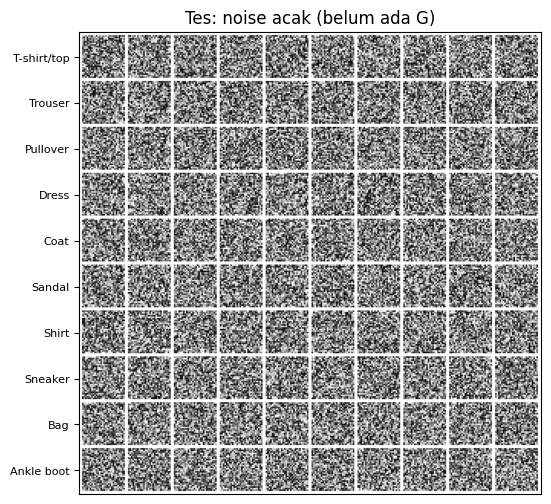

TES 1.2 LULUS
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder keluaran : /content/drive/MyDrive/cgan_fashion_mnist
  checkpoints   : /content/drive/MyDrive/cgan_fashion_mnist/checkpoints
  samples       : /content/drive/MyDrive/cgan_fashion_mnist/samples
  logs          : /content/drive/MyDrive/cgan_fashion_mnist/logs
TES 1.3 LULUS
TES 1.4 LULUS
Generator(
  (embed): Embedding(10, 50)
  (project): Linear(in_features=150, out_features=6272, bias=False)
  (bn0): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act0): ReLU()
  (up): Sequential(
    (0): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e

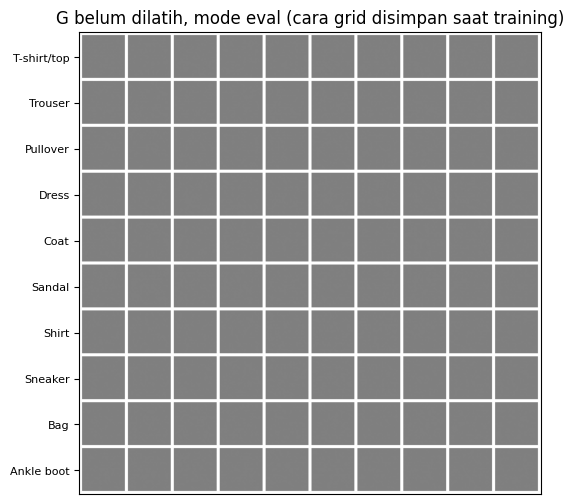

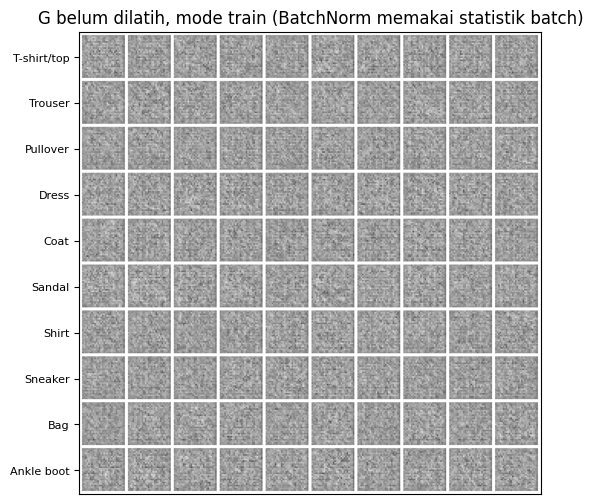

TES 2.5 LULUS
TES 2.6 LULUS


In [20]:
!git clone -q https://github.com/sridewisnn/GEN_AI.git
%run GEN_AI/cGAN_FashionMNIST.ipynb

# Bagian 3: Dataset

## 3.1 Konsep: `get_dataloader`

Bagian ini menyuplai gambar asli ke Discriminator dan ke classifier pendamping.
Kontraknya (cetak biru hlm. 2): `get_dataloader(batch_size)` menghasilkan
`img` [B, 1, 28, 28] float32 di [-1, 1] dan `label` [B] int64 di 0..9.

**Keputusan desain**

| Keputusan | Alasan |
| --- | --- |
| `ToTensor()` lalu `Normalize(CFG.norm_mean, CFG.norm_std)` | G berakhir dengan Tanh, jadi rentangnya [-1, 1]. Gambar asli harus berada di skala yang sama. Kalau tidak, D bisa membedakan asli dan buatan hanya dari skalanya. Nilainya diambil dari CFG, sehingga `denormalize()` selalu menjadi kebalikannya. |
| Tanpa augmentasi | Augmentasi mengubah distribusi yang ingin ditiru G. |
| Train: `shuffle=True`, `drop_last=True` | 60.000 / 128 = 468 sisa 96. Batch sisa dibuang supaya statistik BatchNorm tidak dihitung dari batch kecil. |
| Test (`train=False`): `shuffle=False`, `drop_last=False` | Hanya untuk classifier pendamping. Akurasi harus dihitung dari seluruh 10.000 gambar, dan urutan tidak berpengaruh. |
| `torch.Generator` berseed khusus untuk shuffle | Urutan batch sama di setiap run dan tidak terganggu oleh `torch.randn` di sel lain, tetapi tetap berbeda antar-epoch. |
| `pin_memory = (DEVICE.type == "cuda")` | Mempercepat transfer ke GPU. Di CPU tidak ada gunanya dan hanya memunculkan peringatan. |
| `persistent_workers=True` | Dua worker tidak dimatikan dan dihidupkan lagi di setiap epoch (50 kali). |

Label dibiarkan berupa indeks int64, bukan one-hot, karena `nn.Embedding` di G dan D
menerima indeks kelas secara langsung.

In [21]:
# Import tambahan Bagian 3-4 (tidak ada di cell import Bagian 0).
import math
from torchvision import transforms
from torch.utils.data import DataLoader


def build_transform() -> transforms.Compose:
    """PIL uint8 [0, 255] -> tensor float32 [1, 28, 28] di rentang [-1, 1]."""
    return transforms.Compose([
        # ToTensor: PIL [H, W] uint8 -> [C, H, W] float32, dibagi 255 -> rentang [0, 1].
        transforms.ToTensor(),
        # (x - 0.5) / 0.5 -> rentang [-1, 1], sama dengan rentang keluaran Tanh di G.
        # Nilai diambil dari CFG agar denormalize() di Bagian 1 selalu menjadi kebalikannya.
        transforms.Normalize((CFG.norm_mean,), (CFG.norm_std,)),
    ])


def get_dataset(train: bool = True) -> torchvision.datasets.FashionMNIST:
    """Dataset FashionMNIST (train 60.000 / test 10.000). Unduhan dilewati bila file sudah ada."""
    # download=True aman dijalankan ulang: torchvision memeriksa file di CFG.data_dir lebih dulu.
    return torchvision.datasets.FashionMNIST(
        root=CFG.data_dir, train=train, download=True, transform=build_transform())


def get_dataloader(batch_size: int, train: bool = True) -> DataLoader:
    """Kontrak Bagian 3: setiap batch = (img [B,1,28,28] float32 di [-1,1], label [B] int64 di 0..9).

    train=True : split train, diacak, batch terakhir yang tidak penuh dibuang (untuk GAN).
    train=False: split test, urutan tetap, semua gambar ikut (untuk evaluasi classifier pendamping).
    """
    if not isinstance(batch_size, int) or batch_size <= 0:
        raise ValueError(f"batch_size harus bilangan bulat > 0, diterima {batch_size!r}")

    dataset = get_dataset(train)

    # Generator terpisah untuk shuffle: urutan batch sama di setiap run (reproducible),
    # tetapi tetap berbeda antar-epoch karena generator ini maju setiap kali loader diiterasi.
    # Tidak bergantung pada RNG global, jadi tidak terganggu oleh pemanggilan torch.randn di cell lain.
    shuffle_gen = torch.Generator().manual_seed(CFG.seed) if train else None

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=train,                 # test tidak perlu diacak: akurasi tidak bergantung urutan
        drop_last=train,               # train: batch sisa 96 gambar dibuang agar BatchNorm stabil
        num_workers=CFG.num_workers,   # Colab punya 2 CPU
        # pin_memory hanya berguna (dan hanya didukung tanpa peringatan) bila ada GPU.
        pin_memory=(DEVICE.type == "cuda"),
        # Worker dipertahankan antar-epoch: menghemat waktu start ulang 2 proses di setiap epoch.
        persistent_workers=CFG.num_workers > 0,
        generator=shuffle_gen,
    )


train_loader = get_dataloader(CFG.batch_size, train=True)
test_loader = get_dataloader(CFG.batch_size, train=False)
print(f"train: {len(train_loader.dataset):,} gambar -> {len(train_loader)} batch/epoch")
print(f"test : {len(test_loader.dataset):,} gambar -> {len(test_loader)} batch")

train: 60,000 gambar -> 468 batch/epoch
test : 10,000 gambar -> 79 batch


### Tes 3.1

Memeriksa kontrak antarmuka (bentuk, tipe, rentang), kebenaran rumus normalisasi terhadap
data mentah, keseimbangan kelas, pengaturan loader, reproducibility shuffle,
kelengkapan split test, dan kecocokan bentuk dengan keluaran Generator.

In [22]:
B = CFG.batch_size
img_shape = (CFG.img_channels, CFG.img_size, CFG.img_size)
RANGE_TOL = 1e-6   # toleransi pembulatan float32: piksel 0 dan 255 harus jatuh tepat di -1 dan 1

# --- Tes 3.1a: ukuran dataset dan jumlah batch ---
assert len(train_loader.dataset) == CFG.train_size, f"train berisi {len(train_loader.dataset)}, seharusnya {CFG.train_size}"
assert len(train_loader) == CFG.iters_per_epoch, f"{len(train_loader)} batch/epoch, seharusnya {CFG.iters_per_epoch}"
n_test = len(test_loader.dataset)
assert len(test_loader) == math.ceil(n_test / B), "test tidak boleh membuang batch terakhir"

# --- Tes 3.1b: kontrak bentuk dan tipe satu batch train ---
img, label = next(iter(train_loader))
assert img.shape == (B, *img_shape), f"img {tuple(img.shape)}, seharusnya {(B, *img_shape)}"
assert img.dtype == torch.float32, f"img bertipe {img.dtype}, seharusnya float32"
assert label.shape == (B,), f"label {tuple(label.shape)}, seharusnya ({B},) (bukan one-hot)"
assert label.dtype == torch.int64, f"label bertipe {label.dtype}, seharusnya int64 (wajib untuk nn.Embedding)"
assert 0 <= label.min() and label.max() < CFG.num_classes, f"label di luar 0..{CFG.num_classes - 1}"

# --- Tes 3.1c: rentang [-1, 1], dan kedua ujung benar-benar muncul ---
print(f"rentang batch: [{img.min():.4f}, {img.max():.4f}]")
assert img.min() >= -1 - RANGE_TOL and img.max() <= 1 + RANGE_TOL, "img di luar [-1, 1]"
assert img.min() <= -1 + RANGE_TOL, "tidak ada piksel bernilai -1: normalisasi bergeser (cek mean/std)"
assert img.max() >= 1 - RANGE_TOL, "tidak ada piksel bernilai 1: normalisasi menyempit (cek ToTensor)"

# --- Tes 3.1d: transform persis (x/255 - mean)/std terhadap data mentah ---
ds = train_loader.dataset
for idx in (0, len(ds) - 1):
    raw = ds.data[idx].float() / 255.0                          # uint8 mentah [28, 28]
    expected_img = ((raw - CFG.norm_mean) / CFG.norm_std).unsqueeze(0)
    got_img, got_label = ds[idx]
    assert torch.allclose(got_img, expected_img, atol=RANGE_TOL), f"transform sampel {idx} tidak sesuai rumus"
    assert got_label == ds.targets[idx].item(), f"label sampel {idx} tidak cocok dengan targets"
    # denormalize (Bagian 1) harus mengembalikan gambar mentah: real dan fake memakai skala yang sama.
    assert torch.allclose(denormalize(got_img).squeeze(0), raw, atol=RANGE_TOL), "denormalize tidak membalik transform"

# --- Tes 3.1e: semua kelas ada dan seimbang (6.000 per kelas di train) ---
counts = torch.bincount(ds.targets, minlength=CFG.num_classes)
assert counts.numel() == CFG.num_classes, f"ada label >= {CFG.num_classes}"
assert (counts == CFG.train_size // CFG.num_classes).all(), f"jumlah per kelas tidak seimbang: {counts.tolist()}"

# --- Tes 3.1f: pengaturan loader sesuai cetak biru ---
assert train_loader.drop_last is True and test_loader.drop_last is False
assert isinstance(train_loader.sampler, torch.utils.data.RandomSampler), "train harus diacak"
assert isinstance(test_loader.sampler, torch.utils.data.SequentialSampler), "test tidak boleh diacak"
assert train_loader.num_workers == CFG.num_workers
assert train_loader.pin_memory == (DEVICE.type == "cuda")

# --- Tes 3.1g: shuffle reproducible antar-run, tetapi berbeda antar-epoch ---
_, label_run2 = next(iter(get_dataloader(B, train=True)))      # loader baru = "run baru"
assert torch.equal(label, label_run2), "dua loader baru harus memberi urutan batch yang sama (seed tetap)"
_, label_epoch2 = next(iter(train_loader))                     # iterasi kedua dari loader yang sama = epoch 2
assert not torch.equal(label, label_epoch2), "urutan epoch 2 harus berbeda dari epoch 1"

# --- Tes 3.1h: split test berurutan dan tidak kehilangan gambar ---
_, label_test = next(iter(test_loader))
assert torch.equal(label_test, test_loader.dataset.targets[:B]), "test harus berurutan (shuffle=False)"
total = sum(lbl.numel() for _, lbl in test_loader)
assert total == n_test, f"test loader menyajikan {total} gambar, seharusnya {n_test}"

# --- Tes 3.1i: batch langsung cocok dengan Generator (kontrak lintas bagian) ---
G.eval()
with torch.no_grad():
    fake = G(torch.randn(B, CFG.z_dim, device=DEVICE), label.to(DEVICE))
assert fake.shape == img.shape, f"G menghasilkan {tuple(fake.shape)}, data real {tuple(img.shape)}: D akan menerima dua bentuk berbeda"

# --- Tes 3.1j: input tidak sah ditolak ---
for bad in (0, -1, 12.5):
    try:
        get_dataloader(bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"get_dataloader({bad!r}) seharusnya memunculkan ValueError")

print("TES 3.1 LULUS")

rentang batch: [-1.0000, 1.0000]
TES 3.1 LULUS


## 3.2 Konsep: pemeriksaan visual data

Tes 3.1 membuktikan bentuk, tipe, dan rentang. Tes itu tidak bisa membuktikan bahwa
**gambar dan labelnya berpasangan dengan benar**. Contohnya: gambar sepatu berlabel "Dress",
atau gambar yang terbalik atau terlalu gelap karena normalisasi salah. Hal seperti ini hanya
terlihat oleh mata, dan cetak biru (hlm. 4) mewajibkan pemeriksaan manualnya sebelum training.

**Keputusan desain**

| Keputusan | Alasan |
| --- | --- |
| Gambar diambil dari batch `train_loader`, bukan langsung dari dataset | Yang diperiksa adalah pasangan (gambar, label) yang benar-benar akan diterima D, termasuk efek shuffle. |
| Helper baru `show_labeled_images` dengan judul per gambar | `show_image_grid` (Bagian 1) hanya memberi label per baris. Di batch acak, setiap gambar punya kelas sendiri. Denormalisasinya tetap memakai `denormalize` dari Bagian 1. |
| `vmin=0, vmax=1` saat `imshow` | Tanpa ini matplotlib meregangkan kontras tiap gambar, sehingga gambar yang terlalu gelap atau terang (gejala bug normalisasi) justru tampak normal. |
| Grid acuan real 10×10 (baris ke-i = kelas ke-i) | Tata letaknya sama dengan grid sampel G (`make_fixed_noise`), sehingga `samples/epoch_XXX.png` bisa dibandingkan langsung dengan gambar asli. Isinya deterministik (10 gambar pertama tiap kelas), jadi grid ini sama di setiap run. |

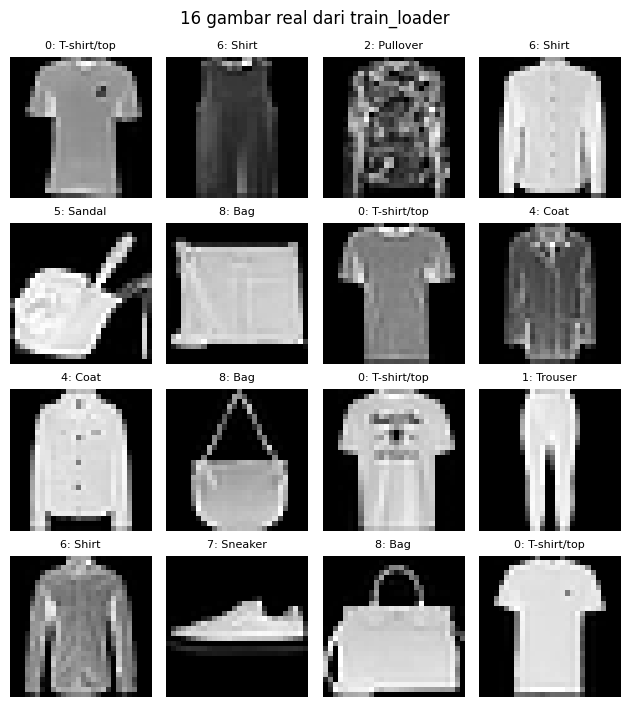

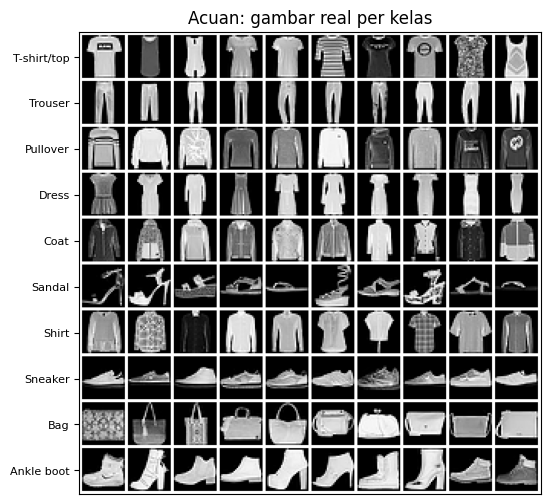

Grid acuan disimpan di: /content/drive/MyDrive/cgan_fashion_mnist/samples/real_reference.png


In [23]:
@dataclass
class PreviewConfig:
    """Pengaturan pemeriksaan visual data (Bagian 3.2). Terpisah dari CFG milik tim."""
    n: int = 16                                # cetak biru hlm. 4: grid 16 gambar real berlabel
    nrow: int = 4                              # 4 x 4: judul tiap gambar masih terbaca
    real_grid_name: str = "real_reference.png" # grid acuan 10 kelas x 10 sampel, disimpan di CFG.sample_dir

    def __post_init__(self):
        if self.n <= 0 or self.nrow <= 0 or self.n % self.nrow != 0:
            raise ValueError(f"n ({self.n}) harus > 0 dan habis dibagi nrow ({self.nrow}).")


PREVIEW_CFG = PreviewConfig()


def show_labeled_images(images: torch.Tensor, labels: torch.Tensor, nrow: int, title: str = None):
    """Tampilkan gambar [N,1,H,W] (rentang [-1,1]) dengan nama kelas di atas TIAP gambar.

    show_image_grid (Bagian 1) hanya bisa memberi label per baris, padahal di batch acak
    tiap gambar punya kelas sendiri. Fungsi ini melengkapinya dan memakai denormalize yang sama.
    Mengembalikan figure agar isinya bisa diperiksa oleh tes.
    """
    if images.size(0) != labels.size(0):
        raise ValueError(f"jumlah gambar ({images.size(0)}) dan label ({labels.size(0)}) berbeda")
    n = images.size(0)
    ncol = math.ceil(n / nrow)
    # detach + cpu: aman untuk tensor di GPU atau yang masih terhubung ke graph gradien.
    imgs01 = denormalize(images.detach().cpu().float())        # [-1,1] -> [0,1], sama seperti grid tim

    fig, axes = plt.subplots(nrow, ncol, figsize=(1.6 * ncol, 1.8 * nrow), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i >= n:
            continue                                           # sel kosong bila n bukan kelipatan
        c = int(labels[i])
        # vmin/vmax tetap: tanpa ini matplotlib meregangkan kontras tiap gambar dan
        # gambar yang terlalu gelap/terang (gejala bug normalisasi) tidak akan terlihat.
        ax.imshow(imgs01[i, 0].numpy(), cmap="gray", vmin=0.0, vmax=1.0)
        ax.set_title(f"{c}: {CLASS_NAMES[c]}", fontsize=8)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    return fig


def real_reference_indices(dataset, n_per_class: int) -> torch.Tensor:
    """Indeks n_per_class gambar pertama tiap kelas, diurutkan kelas 0..9 (deterministik, tanpa acak)."""
    idx = [torch.nonzero(dataset.targets == c).flatten()[:n_per_class]
           for c in range(CFG.num_classes)]
    return torch.cat(idx)                                      # baris ke-c = kelas c, sama dengan make_fixed_noise


# --- (a) Wajib cetak biru: 16 gambar pertama dari batch train_loader, label di judul tiap gambar ---
# Diambil dari loader (bukan dari dataset langsung) agar yang diperiksa adalah pasangan
# (gambar, label) yang benar-benar akan diterima D saat training.
preview_img, preview_label = next(iter(train_loader))
preview_img, preview_label = preview_img[:PREVIEW_CFG.n], preview_label[:PREVIEW_CFG.n]
fig_preview = show_labeled_images(preview_img, preview_label, PREVIEW_CFG.nrow,
                                  title=f"{PREVIEW_CFG.n} gambar real dari train_loader")

# --- (b) Grid acuan real: tata letak sama dengan grid sampel G (baris ke-i = kelas ke-i) ---
# Dibandingkan berdampingan dengan samples/epoch_XXX.png saat evaluasi dan presentasi.
ref_ds = train_loader.dataset
ref_idx = real_reference_indices(ref_ds, CFG.n_per_class_grid)
ref_imgs = torch.stack([ref_ds[i][0] for i in ref_idx.tolist()])     # [100, 1, 28, 28] di [-1, 1]
ref_path = os.path.join(CFG.sample_dir, PREVIEW_CFG.real_grid_name)
ref_grid = save_image_grid(ref_imgs, ref_path)                       # menimpa file lama: aman dijalankan ulang
show_image_grid(ref_grid, "Acuan: gambar real per kelas", row_labels=CLASS_NAMES)
print("Grid acuan disimpan di:", ref_path)

### Tes 3.2

Bagian otomatis memastikan bahwa yang tampil adalah data yang benar: judul sesuai label,
piksel sesuai tensornya, skala warna tetap, grid acuan berurutan per kelas dan berukuran
sama dengan grid G. Penilaian akhir tetap **cek manual** dengan daftar di bawah sel tes.

In [24]:
GRID_PAD = 2   # padding yang dipakai save_image_grid di Bagian 1 (make_grid padding=2)
PIX_TOL = 1e-6

# --- Tes 3.2a: preview berisi n gambar, judul tiap gambar = nama kelas labelnya ---
shown = [ax for ax in fig_preview.axes if ax.images]
assert len(shown) == PREVIEW_CFG.n, f"{len(shown)} gambar tampil, seharusnya {PREVIEW_CFG.n}"
for i, ax in enumerate(shown):
    c = int(preview_label[i])
    assert ax.get_title() == f"{c}: {CLASS_NAMES[c]}", f"gambar {i}: judul '{ax.get_title()}' tidak sesuai label {c}"
    # Piksel yang tampil harus persis gambar ke-i setelah denormalize (urutan gambar-label tidak tertukar).
    shown_pix = torch.from_numpy(np.asarray(ax.images[0].get_array(), dtype=np.float32))
    assert torch.allclose(shown_pix, denormalize(preview_img[i, 0]), atol=PIX_TOL), f"gambar {i} tidak cocok dengan tensornya"
    assert ax.images[0].get_clim() == (0.0, 1.0), "skala warna harus tetap [0, 1] agar gambar gelap/terang terlihat apa adanya"

# --- Tes 3.2b: grid acuan, baris ke-c benar-benar kelas c ---
n_ref = CFG.num_classes * CFG.n_per_class_grid
assert ref_idx.numel() == n_ref, f"{ref_idx.numel()} indeks acuan, seharusnya {n_ref}"
ref_labels = ref_ds.targets[ref_idx]
expected_rows = torch.arange(CFG.num_classes).repeat_interleave(CFG.n_per_class_grid)
assert torch.equal(ref_labels, expected_rows), "urutan grid acuan harus baris ke-i = kelas ke-i (sama dengan make_fixed_noise)"
_, y_fixed_check = make_fixed_noise(device="cpu")
assert torch.equal(ref_labels, y_fixed_check), "tata letak grid acuan berbeda dengan grid sampel G"
assert ref_imgs.shape == (n_ref, CFG.img_channels, CFG.img_size, CFG.img_size), ref_imgs.shape
assert ref_imgs.min() >= -1 - PIX_TOL and ref_imgs.max() <= 1 + PIX_TOL

# --- Tes 3.2c: file grid acuan tersimpan dengan ukuran yang sama dengan grid sampel G ---
side = CFG.n_per_class_grid * (CFG.img_size + GRID_PAD) + GRID_PAD
assert os.path.isfile(ref_path), f"file tidak terbentuk: {ref_path}"
assert Image.open(ref_path).size == (side, side), f"ukuran {Image.open(ref_path).size}, seharusnya {(side, side)}"
assert ref_grid.shape == (3, side, side), ref_grid.shape

# --- Tes 3.2d: deterministik (dijalankan ulang memberi grid acuan yang sama) ---
assert torch.equal(real_reference_indices(ref_ds, CFG.n_per_class_grid), ref_idx), "indeks acuan harus tetap"

# --- Tes 3.2e: input tidak sah ditolak ---
try:
    show_labeled_images(preview_img[:4], preview_label[:3], nrow=2)
except ValueError:
    pass
else:
    raise AssertionError("jumlah gambar dan label berbeda seharusnya memunculkan ValueError")
try:
    PreviewConfig(n=16, nrow=5)
except ValueError:
    pass
else:
    raise AssertionError("PreviewConfig(n=16, nrow=5) seharusnya memunculkan ValueError")

plt.close("all")   # bebaskan figure agar menjalankan ulang tidak menumpuk memori
print("TES 3.2 LULUS  (lanjutkan dengan cek manual di bawah)")

TES 3.2 LULUS  (lanjutkan dengan cek manual di bawah)


# Bagian 4: Classifier pendamping + generate

## 4a Konsep: classifier pendamping

Classifier ini adalah **alat ukur independen** untuk Bagian 7. Pertanyaan yang dijawabnya:
"kalau G diminta membuat Sneaker, apakah hasilnya benar-benar dikenali sebagai Sneaker?"
Classifier tidak ikut dalam training GAN. Ia dilatih sekali pada Fashion-MNIST **asli**,
lalu dibekukan.

**Kontrak** (cetak biru hlm. 2): gambar [B, 1, 28, 28] di [-1, 1] → logit [B, 10].

| Keputusan | Alasan |
| --- | --- |
| CNN kecil 2 blok Conv-ReLU-MaxPool, `padding=1` | Resolusi 28 → 14 → 7, sama dengan pola G dan D. Flatten = 64·7·7 = 3136. Sekitar 0,42 juta parameter, cukup untuk sekitar 91% dan cepat di CPU. |
| Input dinormalisasi ke [-1, 1] lewat `get_dataloader` yang sama | Gambar buatan G juga berada di [-1, 1]. Classifier harus menilai keduanya di skala yang sama, kalau tidak akurasinya turun karena skala, bukan karena kualitas gambar. |
| Logit mentah + `CrossEntropyLoss` | Log-softmax sudah ada di dalam loss dan stabil secara numerik. |
| Adam lr 1e-3, beta default | Classifier punya target tetap. β1 = 0,5 hanya dibutuhkan GAN karena lawannya terus berubah. |
| Init default PyTorch, bukan `weights_init` | N(0; 0,02) adalah konvensi khusus GAN. Untuk classifier biasa, init Kaiming default sudah stabil. |
| `ClassifierConfig` terpisah dari `CFG` | `CFG` dikelola ketua. Semua angka classifier ada di satu tempat ini, dan path tetap diambil dari `CFG.ckpt_dir`. |
| Dibekukan (`eval()` + `requires_grad=False`) lalu disimpan ke Drive | Alat ukur tidak boleh berubah antar-pengukuran. Bobot di Drive bertahan antar-sesi, jadi training cukup sekali. |

In [25]:
import time
from tqdm.auto import tqdm   # progress bar dengan estimasi sisa waktu (bawaan Colab)


@dataclass
class ClassifierConfig:
    """Hyperparameter classifier pendamping (cetak biru hlm. 13). Terpisah dari CFG milik tim."""
    clf_epochs: int = 5
    clf_lr: float = 1e-3
    clf_channels: Tuple[int, ...] = (32, 64)   # kanal tiap blok Conv-ReLU-MaxPool: 28 -> 14 -> 7
    clf_hidden: int = 128                     # lebar layer tersembunyi sebelum logit
    clf_min_test_acc: float = 0.88            # ambang tes: sedikit di bawah ±91% agar tahan variasi antar-run
    clf_weights_name: str = "classifier.pt"   # TIDAK diawali "ckpt_epoch": latest_checkpoint() tim tidak tertukar

    def __post_init__(self):
        if self.clf_epochs <= 0 or self.clf_lr <= 0 or self.clf_hidden <= 0:
            raise ValueError("clf_epochs, clf_lr, dan clf_hidden harus > 0.")
        if not self.clf_channels or any(c <= 0 for c in self.clf_channels):
            raise ValueError("clf_channels harus berisi minimal satu bilangan > 0.")
        if CFG.img_size % (2 ** len(self.clf_channels)) != 0:
            raise ValueError(f"img_size ({CFG.img_size}) harus habis dibagi 2^{len(self.clf_channels)} "
                             "(setiap blok MaxPool membagi dua resolusi).")
        if not (0.0 < self.clf_min_test_acc <= 1.0):
            raise ValueError("clf_min_test_acc harus di rentang (0, 1].")
        if self.clf_weights_name.startswith("ckpt_epoch"):
            raise ValueError("clf_weights_name tidak boleh diawali 'ckpt_epoch' (bentrok dengan checkpoint GAN).")

    @property
    def weights_path(self) -> str:
        # Dihitung saat dipakai (bukan disimpan): selalu mengikuti CFG.ckpt_dir terbaru (Drive atau lokal).
        return os.path.join(CFG.ckpt_dir, self.clf_weights_name)

    @property
    def feat_size(self) -> int:
        return CFG.img_size // 2 ** len(self.clf_channels)          # 28 // 4 = 7

    @property
    def flat_dim(self) -> int:
        return self.clf_channels[-1] * self.feat_size ** 2          # 64 * 7 * 7 = 3136


CLF_CFG = ClassifierConfig()


class Classifier(nn.Module):
    """Classifier pendamping: gambar [B,1,28,28] di [-1,1] -> logit [B,10] (tanpa softmax).

    Alur (konfigurasi baseline):
      Conv(1->32, k3, p1) -> ReLU -> MaxPool(2)   [B, 32, 14, 14]
      Conv(32->64, k3, p1) -> ReLU -> MaxPool(2)  [B, 64,  7,  7]
      Flatten                                     [B, 3136]
      Linear(3136->128) -> ReLU                   [B, 128]
      Linear(128->10)                             [B, 10]  (logit)
    """

    def __init__(self):
        super().__init__()
        blocks, c_in = [], CFG.img_channels
        for c_out in CLF_CFG.clf_channels:
            # padding=1 dengan kernel 3: ukuran tetap, MaxPool yang membagi dua (28->14->7,
            # sama dengan pola G dan D). Piksel tepi tidak terbuang.
            blocks += [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
                       nn.ReLU(),
                       nn.MaxPool2d(kernel_size=2)]
            c_in = c_out
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(CLF_CFG.flat_dim, CLF_CFG.clf_hidden),
            nn.ReLU(),
            # Logit mentah: CrossEntropyLoss sudah memuat log-softmax (stabil secara numerik).
            nn.Linear(CLF_CFG.clf_hidden, CFG.num_classes),
        )
        # Sengaja TIDAK memakai weights_init (N(0, 0.02)) milik GAN: itu konvensi khusus GAN.
        # Classifier biasa sudah stabil dengan init default PyTorch (Kaiming-uniform).

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        expected = (CFG.img_channels, CFG.img_size, CFG.img_size)
        if x.dim() != 4 or tuple(x.shape[1:]) != expected:
            raise ValueError(f"x harus berbentuk [B, {', '.join(map(str, expected))}], diterima {tuple(x.shape)}")
        # Rentang [-1, 1] sengaja tidak dicek di sini: memaksa sinkronisasi GPU tiap batch
        # (alasan yang sama dengan Generator). Rentang sudah dijamin oleh Tes 3.1 dan Tanh di G.
        return self.head(self.features(x))


set_seed(CFG.seed)
_clf_preview = Classifier()
print(_clf_preview)
print(f"\nflatten = {CLF_CFG.flat_dim}, jumlah parameter = {sum(p.numel() for p in _clf_preview.parameters()):,}")

Classifier(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

flatten = 3136, jumlah parameter = 421,642


### Tes 4a.1 (arsitektur, sebelum training)

Dijalankan **sebelum** training supaya kesalahan bentuk ketahuan dalam hitungan detik,
bukan setelah menunggu beberapa menit. Yang diperiksa: bentuk tiap tahap, kontrak keluaran,
jumlah parameter, kecocokan dengan batch dari Bagian 3, aliran gradien, dan penolakan input salah.

In [26]:
clf_t = Classifier().to(DEVICE)
B = CFG.batch_size

# --- Tes 4a.1a: bentuk tiap tahap (dicatat lewat forward hook) ---
shapes = {}
hooks = [m.register_forward_hook(lambda m, i, o, n=n: shapes.__setitem__(n, tuple(o.shape)))
         for n, m in clf_t.named_modules() if len(list(m.children())) == 0]
x_rand = torch.rand(B, CFG.img_channels, CFG.img_size, CFG.img_size, device=DEVICE) * 2 - 1   # di [-1, 1]
with torch.no_grad():
    logits = clf_t(x_rand)
for h in hooks:
    h.remove()

side = CFG.img_size
for k, c in enumerate(CLF_CFG.clf_channels):           # blok ke-k: Conv di indeks 3k, MaxPool di 3k+2
    assert shapes[f"features.{3 * k}"] == (B, c, side, side), f"Conv blok {k}: {shapes[f'features.{3 * k}']}"
    side //= 2
    assert shapes[f"features.{3 * k + 2}"] == (B, c, side, side), f"MaxPool blok {k}: {shapes[f'features.{3 * k + 2}']}"
assert side == CLF_CFG.feat_size
assert shapes["head.0"] == (B, CLF_CFG.flat_dim), f"Flatten {shapes['head.0']}, seharusnya {(B, CLF_CFG.flat_dim)}"
assert CLF_CFG.flat_dim == 3136, f"flat_dim {CLF_CFG.flat_dim}, keputusan tim: 3136 (padding=1)"

# --- Tes 4a.1b: kontrak keluaran ---
assert logits.shape == (B, CFG.num_classes), f"logit {tuple(logits.shape)}, seharusnya {(B, CFG.num_classes)}"
assert logits.dtype == torch.float32
assert torch.isfinite(logits).all(), "ada NaN/Inf di logit"
# Logit mentah, bukan probabilitas: baris tidak dijumlah ke 1 dan boleh negatif.
assert not torch.allclose(logits.sum(1), torch.ones(B, device=DEVICE)), "keluaran tampak sudah di-softmax"

# --- Tes 4a.1c: pengaturan layer dan jumlah parameter ---
for k in range(len(CLF_CFG.clf_channels)):
    conv = clf_t.features[3 * k]
    assert (conv.kernel_size, conv.padding) == ((3, 3), (1, 1)), f"Conv blok {k} harus k=3, padding=1"
expected_params, c_in = 0, CFG.img_channels
for c in CLF_CFG.clf_channels:
    expected_params += c * c_in * 3 * 3 + c             # bobot kernel 3x3 + bias
    c_in = c
expected_params += CLF_CFG.flat_dim * CLF_CFG.clf_hidden + CLF_CFG.clf_hidden
expected_params += CLF_CFG.clf_hidden * CFG.num_classes + CFG.num_classes
n_params = sum(p.numel() for p in clf_t.parameters())
assert n_params == expected_params, f"{n_params:,} parameter, seharusnya {expected_params:,}"

# --- Tes 4a.1d: batch dari get_dataloader langsung bisa masuk (kontrak Bagian 3 -> 4) ---
img_real, _ = next(iter(test_loader))
with torch.no_grad():
    out_real = clf_t(img_real.to(DEVICE))
assert out_real.shape == (img_real.size(0), CFG.num_classes) and torch.isfinite(out_real).all()

# --- Tes 4a.1e: gradien sampai ke semua parameter (classifier bisa dilatih) ---
clf_t.zero_grad()
nn.functional.cross_entropy(clf_t(x_rand[:8]), torch.randint(0, CFG.num_classes, (8,), device=DEVICE)).backward()
bad = [n for n, p in clf_t.named_parameters() if p.grad is None or not torch.isfinite(p.grad).all()]
assert not bad, f"parameter tanpa gradien sah: {bad}"

# --- Tes 4a.1f: input salah ditolak dengan pesan jelas ---
for bad_x in (torch.zeros(4, 28, 28), torch.zeros(4, 3, 28, 28), torch.zeros(4, 1, 32, 32)):
    try:
        clf_t(bad_x.to(DEVICE))
    except ValueError:
        pass
    else:
        raise AssertionError(f"input {tuple(bad_x.shape)} seharusnya ditolak")
for bad_kw in (dict(clf_channels=()), dict(clf_min_test_acc=1.5), dict(clf_weights_name="ckpt_epoch_clf.pt")):
    try:
        ClassifierConfig(**bad_kw)
    except ValueError:
        pass
    else:
        raise AssertionError(f"ClassifierConfig({bad_kw}) seharusnya ditolak")

del clf_t
print("TES 4a.1 LULUS")

TES 4a.1 LULUS


## 4a (lanjutan): training, evaluasi, simpan, dan muat

| Fungsi | Peran |
| --- | --- |
| `train_classifier(model, loader)` | Melatih model dan mencetak loss, akurasi, `s/epoch`, serta sisa waktu. tqdm menampilkan estimasi waktu di dalam epoch. |
| `evaluate_classifier(model, loader)` | Menghitung akurasi total, per kelas, dan confusion matrix. Menerima DataLoader **atau** list `[(img, label)]`, jadi Bagian 7 bisa langsung memasukkan gambar buatan G. |
| `print_accuracy_table(result)` | Menampilkan tabel per kelas dengan `CLASS_NAMES`. |
| `load_classifier(path)` | Mengembalikan model di `DEVICE`, mode eval, beku. Config arsitektur dicek dulu agar error-nya jelas. |
| `get_or_train_classifier()` | Kalau `classifier.pt` sudah ada di `CFG.ckpt_dir`, bobot dimuat saja. Kalau belum, model dilatih, dievaluasi, disimpan secara atomik, lalu dimuat ulang dari file. `force_retrain=True` memaksa training ulang. |

**Akurasi total** dilaporkan dua cara. *Micro* (benar/total) dan *rata-rata kelas* (definisi
cetak biru hlm. 13). Pada test set yang seimbang keduanya sama. Bedanya baru terlihat di
Bagian 7 kalau jumlah gambar per kelas tidak sama.

In [27]:
def freeze(model: nn.Module) -> nn.Module:
    """Bekukan model sebagai alat ukur: mode eval dan tanpa gradien."""
    model.eval()
    model.requires_grad_(False)   # tidak bisa ikut ter-update walau tidak sengaja masuk optimizer
    return model


def train_classifier(model: nn.Module, loader, epochs: int = None, lr: float = None) -> list:
    """Latih classifier pada gambar ASLI. Mencetak loss, akurasi, dan waktu per epoch.

    Mengembalikan riwayat per epoch: [{"epoch", "loss", "acc", "sec"}, ...].
    """
    epochs = CLF_CFG.clf_epochs if epochs is None else epochs
    lr = CLF_CFG.clf_lr if lr is None else lr
    model.to(DEVICE)
    # Adam lr 1e-3 dengan beta default (0.9, 0.999): beta1=0.5 milik GAN hanya perlu
    # karena lawannya berubah-ubah; classifier punya target tetap.
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    non_blocking = DEVICE.type == "cuda"      # salin async hanya bermakna dengan pin_memory di GPU

    print(f"Training classifier di {DEVICE.type.upper()}: {epochs} epoch x {len(loader)} batch")
    history, t_start = [], time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.perf_counter()
        loss_sum, correct, seen = 0.0, 0, 0
        # tqdm menampilkan kecepatan dan estimasi sisa waktu epoch berjalan;
        # leave=False: bar hilang setelah selesai, yang tertinggal hanya ringkasan per epoch.
        for img, label in tqdm(loader, desc=f"epoch {epoch}/{epochs}", leave=False):
            img = img.to(DEVICE, non_blocking=non_blocking)
            label = label.to(DEVICE, non_blocking=non_blocking)
            logits = model(img)
            loss = loss_fn(logits, label)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            # Akumulasi sebagai tensor (detach: graph tidak tertahan) tanpa .item() per langkah:
            # .item() memaksa CPU menunggu GPU di setiap batch. Dikonversi sekali di akhir epoch.
            loss_sum += loss.detach() * label.size(0)
            correct += (logits.argmax(1) == label).sum()
            seen += label.size(0)

        sec = time.perf_counter() - t0
        rec = {"epoch": epoch, "loss": loss_sum.item() / seen, "acc": correct.item() / seen, "sec": sec}
        history.append(rec)
        # Sisa waktu dari rata-rata epoch yang sudah selesai (epoch 1 sedikit lebih lambat: worker start).
        eta = (time.perf_counter() - t_start) / epoch * (epochs - epoch)
        print(f"epoch {epoch}/{epochs} | loss {rec['loss']:.4f} | train acc {rec['acc']:.2%} "
              f"| {sec:5.1f} s/epoch | sisa ~{eta / 60:.1f} menit")
    print(f"Selesai dalam {(time.perf_counter() - t_start) / 60:.1f} menit.")
    return history


@torch.no_grad()
def evaluate_classifier(model: nn.Module, loader) -> dict:
    """Akurasi total dan per kelas.

    loader: apa pun yang menghasilkan pasangan (img [B,1,28,28] di [-1,1], label [B] int64),
    misalnya DataLoader Bagian 3, atau list [(gambar_buatan_G, label)] untuk Bagian 7.
    Kembalian:
      acc        : benar / total (micro)
      acc_macro  : rata-rata akurasi kelas yang muncul (definisi "akurasi total" cetak biru hlm. 13)
      per_class  : tensor [10], NaN untuk kelas yang tidak ada di data
      n_per_class: tensor [10], jumlah sampel tiap kelas
      confusion  : tensor [10, 10], baris = label benar, kolom = prediksi
    """
    was_training = model.training
    model.eval()
    k = CFG.num_classes
    confusion = torch.zeros(k, k, dtype=torch.long)
    for img, label in loader:
        pred = model(img.to(DEVICE)).argmax(1).cpu()
        label = label.cpu().long()
        # bincount atas indeks (benar * k + prediksi) = confusion matrix tanpa loop Python.
        confusion += torch.bincount(label * k + pred, minlength=k * k).view(k, k)
    model.train(was_training)                  # kembalikan mode semula: fungsi ini tanpa efek samping

    n_per_class = confusion.sum(1)
    if n_per_class.sum() == 0:
        raise ValueError("loader tidak berisi satu gambar pun")
    per_class = confusion.diag().float() / n_per_class.float()   # 0/0 -> NaN untuk kelas yang tidak ada
    present = n_per_class > 0
    return {
        "acc": (confusion.diag().sum() / n_per_class.sum()).item(),
        "acc_macro": per_class[present].mean().item(),
        "per_class": per_class,
        "n_per_class": n_per_class,
        "confusion": confusion,
    }


def print_accuracy_table(result: dict, title: str = "Akurasi classifier") -> None:
    """Tabel akurasi per kelas dengan CLASS_NAMES."""
    print(f"{title}\n{'kelas':<16}{'n':>7}{'akurasi':>10}")
    print("-" * 33)
    for c, name in enumerate(CLASS_NAMES):
        n = int(result["n_per_class"][c])
        acc = result["per_class"][c].item()
        print(f"{c}: {name:<13}{n:>7}{'-' if n == 0 else f'{acc:.2%}':>10}")
    print("-" * 33)
    print(f"{'total (micro)':<16}{int(result['n_per_class'].sum()):>7}{result['acc']:>10.2%}")
    print(f"{'rata-rata kelas':<16}{'':>7}{result['acc_macro']:>10.2%}")


# Field yang menentukan arsitektur/skala input. Bila berbeda dengan file bobot, state_dict
# tidak cocok atau (lebih berbahaya) cocok tetapi gambar dinilai di skala yang salah.
_CLF_ARCH_KEYS = ("clf_channels", "clf_hidden")
_CFG_ARCH_KEYS = ("img_size", "img_channels", "num_classes", "norm_mean", "norm_std")


def save_classifier(model: nn.Module, path: str, test_result: dict, history: list) -> None:
    payload = {
        "state_dict": model.state_dict(),
        "clf_config": asdict(CLF_CFG),
        "data_config": {k: getattr(CFG, k) for k in _CFG_ARCH_KEYS},
        "test_acc": test_result["acc"],
        "test_per_class": test_result["per_class"],
        "history": history,
    }
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp_path = path + ".tmp"
    torch.save(payload, tmp_path)   # pola atomik yang sama dengan save_checkpoint tim:
    os.replace(tmp_path, path)      # Colab putus di tengah tidak meninggalkan file rusak


def load_classifier(path: str = None) -> nn.Module:
    """Muat classifier siap pakai untuk Bagian 7: di DEVICE, mode eval, beku."""
    path = CLF_CFG.weights_path if path is None else path
    if not os.path.isfile(path):
        raise FileNotFoundError(f"bobot classifier tidak ditemukan: {path}. Jalankan get_or_train_classifier() dulu.")
    payload = torch.load(path, map_location=DEVICE, weights_only=True)
    # Validasi dulu, baru load_state_dict: pesan error jadi jelas, bukan "size mismatch" yang membingungkan.
    as_cmp = lambda v: tuple(v) if isinstance(v, (list, tuple)) else v   # tuple vs list setelah simpan-muat
    mismatch = [f"CLF_CFG.{k}: file={payload['clf_config'][k]}, sekarang={getattr(CLF_CFG, k)}"
                for k in _CLF_ARCH_KEYS if as_cmp(payload["clf_config"][k]) != as_cmp(getattr(CLF_CFG, k))]
    mismatch += [f"CFG.{k}: file={payload['data_config'][k]}, sekarang={getattr(CFG, k)}"
                 for k in _CFG_ARCH_KEYS if payload["data_config"][k] != getattr(CFG, k)]
    if mismatch:
        raise ValueError("config file bobot classifier tidak cocok dengan config sekarang:\n  "
                         + "\n  ".join(mismatch) + "\nLatih ulang dengan get_or_train_classifier(force_retrain=True).")
    model = Classifier().to(DEVICE)
    model.load_state_dict(payload["state_dict"])
    return freeze(model)


def get_or_train_classifier(force_retrain: bool = False) -> nn.Module:
    """Muat bobot bila sudah ada di CFG.ckpt_dir; kalau belum, latih, uji, simpan, lalu muat."""
    path = CLF_CFG.weights_path
    if os.path.isfile(path) and not force_retrain:
        print(f"Bobot ditemukan, training dilewati: {path}")
        return load_classifier(path)

    set_seed(CFG.seed)                                   # bobot awal dan urutan data sama di setiap run
    model = Classifier()
    history = train_classifier(model, get_dataloader(CFG.batch_size, train=True))
    test_result = evaluate_classifier(model, get_dataloader(CFG.batch_size, train=False))
    save_classifier(model, path, test_result, history)
    print(f"Bobot disimpan: {path}")
    # Dimuat ulang dari file: yang dipakai sesudah ini persis sama dengan yang dipakai Bagian 7.
    return load_classifier(path)


clf = get_or_train_classifier()
clf_test = evaluate_classifier(clf, test_loader)
print_accuracy_table(clf_test, "Akurasi classifier pada test set ASLI (batas atas metrik Bagian 7)")

Training classifier di CPU: 5 epoch x 468 batch


epoch 1/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 1/5 | loss 0.4913 | train acc 82.53% | 101.3 s/epoch | sisa ~6.8 menit


epoch 2/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 2/5 | loss 0.3123 | train acc 88.76% |  97.5 s/epoch | sisa ~5.0 menit


...

epoch 3/5 | loss 0.2636 | train acc 90.44% |  99.0 s/epoch | sisa ~3.3 menit


epoch 4/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 4/5 | loss 0.2321 | train acc 91.48% |  99.3 s/epoch | sisa ~1.7 menit


epoch 5/5:   0%|          | 0/468 [00:00<?, ?it/s]

epoch 5/5 | loss 0.2086 | train acc 92.38% |  97.8 s/epoch | sisa ~0.0 menit
Selesai dalam 8.2 menit.
Bobot disimpan: /content/drive/MyDrive/cgan_fashion_mnist/checkpoints/classifier.pt
Akurasi classifier pada test set ASLI (batas atas metrik Bagian 7)
kelas                 n   akurasi
---------------------------------
0: T-shirt/top     1000    90.60%
1: Trouser         1000    98.70%
2: Pullover        1000    81.20%
3: Dress           1000    88.50%
4: Coat            1000    89.20%
5: Sandal          1000    97.90%
6: Shirt           1000    76.40%
7: Sneaker         1000    97.70%
8: Bag             1000    98.10%
9: Ankle boot      1000    96.40%
---------------------------------
total (micro)     10000    91.47%
rata-rata kelas            91.47%


### Tes 4a.2 (setelah training)

Yang diperiksa: akurasi ≥ ambang, konsistensi internal `evaluate_classifier` (termasuk
dibandingkan dengan hitungan langsung), status beku, input berupa list untuk Bagian 7,
muat ulang identik, lewati-training, dan penolakan file dengan config berbeda.

In [28]:
ACC_TOL = 1e-6
n_test = len(test_loader.dataset)
k = CFG.num_classes

# --- Tes 4a.2a: akurasi test >= ambang ---
print(f"akurasi test: {clf_test['acc']:.2%} (ambang {CLF_CFG.clf_min_test_acc:.0%})")
assert clf_test["acc"] >= CLF_CFG.clf_min_test_acc, (
    f"akurasi test {clf_test['acc']:.2%} < {CLF_CFG.clf_min_test_acc:.0%}: classifier belum layak jadi alat ukur. "
    "Periksa normalisasi (Tes 3.1) lalu latih ulang dengan get_or_train_classifier(force_retrain=True).")

# --- Tes 4a.2b: hasil evaluate konsisten secara internal ---
cm = clf_test["confusion"]
assert cm.shape == (k, k) and int(cm.sum()) == n_test, f"confusion berisi {int(cm.sum())} sampel, seharusnya {n_test}"
assert (clf_test["n_per_class"] == n_test // k).all(), "test set harus seimbang (1.000 per kelas)"
assert torch.allclose(clf_test["per_class"], cm.diag().float() / cm.sum(1).float()), "per_class tidak cocok dengan confusion"
assert ((clf_test["per_class"] >= 0) & (clf_test["per_class"] <= 1)).all()
# Pada data seimbang, rata-rata per kelas (definisi cetak biru) = akurasi micro.
assert abs(clf_test["acc"] - clf_test["acc_macro"]) < ACC_TOL, "pada test set seimbang, micro dan macro harus sama"
# Pembanding independen: hitung ulang akurasi dengan cara paling sederhana.
correct_simple = 0
with torch.no_grad():
    for img, label in test_loader:
        correct_simple += (clf(img.to(DEVICE)).argmax(1).cpu() == label).sum().item()
assert abs(correct_simple / n_test - clf_test["acc"]) < ACC_TOL, "evaluate_classifier tidak cocok dengan hitungan langsung"

# --- Tes 4a.2c: model siap pakai sebagai alat ukur (eval, beku, di DEVICE) ---
assert not clf.training, "classifier harus dalam mode eval"
assert not any(p.requires_grad for p in clf.parameters()), "classifier harus dibekukan (requires_grad=False)"
assert next(clf.parameters()).device.type == DEVICE.type
x_check = next(iter(test_loader))[0][:8].to(DEVICE)
assert torch.equal(clf(x_check), clf(x_check)), "keluaran harus deterministik di mode eval"
with torch.no_grad():
    out = clf(x_check)
assert out.shape == (8, k) and torch.isfinite(out).all()

# --- Tes 4a.2d: evaluate menerima list (img, label) untuk Bagian 7, termasuk satu kelas saja ---
img_b, label_b = next(iter(test_loader))
one_class = 7
mask = label_b == one_class
res_list = evaluate_classifier(clf, [(img_b[mask], label_b[mask])])
assert int(res_list["n_per_class"].sum()) == int(mask.sum()) and int(res_list["n_per_class"][one_class]) == int(mask.sum())
assert torch.isnan(res_list["per_class"][torch.arange(k) != one_class]).all(), "kelas yang tidak ada harus NaN, bukan 0"
assert abs(res_list["acc_macro"] - res_list["per_class"][one_class].item()) < ACC_TOL
# evaluate tidak boleh mengubah mode model
clf.train(); evaluate_classifier(clf, [(img_b, label_b)]); assert clf.training, "evaluate harus mengembalikan mode semula"
clf.eval()

# --- Tes 4a.2e: file bobot tersimpan dan bisa dimuat ulang identik ---
path = CLF_CFG.weights_path
assert os.path.isfile(path), f"file bobot tidak ada: {path}"
assert not os.path.basename(path).startswith("ckpt_epoch"), "nama file bobot bentrok dengan checkpoint GAN"
assert latest_checkpoint() is None or os.path.basename(latest_checkpoint()) != CLF_CFG.clf_weights_name
clf_again = load_classifier(path)
assert all(torch.equal(a, b) for a, b in zip(clf.state_dict().values(), clf_again.state_dict().values())), "bobot hasil muat ulang berbeda"
payload = torch.load(path, map_location="cpu", weights_only=True)
assert len(payload["history"]) == CLF_CFG.clf_epochs, "riwayat training harus berisi satu catatan per epoch"
assert abs(payload["test_acc"] - clf_test["acc"]) < ACC_TOL, "akurasi tersimpan berbeda dengan hasil evaluasi sekarang"

# --- Tes 4a.2f: mekanisme lewati-training (file tidak ditulis ulang, cepat) ---
mtime_before = os.path.getmtime(path)
t0 = time.perf_counter()
clf_skip = get_or_train_classifier()
assert os.path.getmtime(path) == mtime_before, "file bobot ditulis ulang: training seharusnya dilewati"
assert time.perf_counter() - t0 < payload["history"][0]["sec"], "memuat bobot seharusnya jauh lebih cepat dari 1 epoch training"
assert all(torch.equal(a, b) for a, b in zip(clf.state_dict().values(), clf_skip.state_dict().values()))

# --- Tes 4a.2g: file dengan config berbeda ditolak dengan pesan jelas ---
with tempfile.TemporaryDirectory() as tmp:
    bad = dict(payload)
    bad["clf_config"] = {**payload["clf_config"], "clf_hidden": CLF_CFG.clf_hidden * 2}
    bad_path = os.path.join(tmp, "clf_bad.pt")
    torch.save(bad, bad_path)
    try:
        load_classifier(bad_path)
    except ValueError as err:
        assert "clf_hidden" in str(err), "pesan error harus menyebut field yang berbeda"
    else:
        raise AssertionError("file dengan clf_hidden berbeda seharusnya ditolak")
    try:
        load_classifier(os.path.join(tmp, "tidak_ada.pt"))
    except FileNotFoundError:
        pass
    else:
        raise AssertionError("path yang tidak ada seharusnya memunculkan FileNotFoundError")

print("TES 4a.2 LULUS")

akurasi test: 91.47% (ambang 88%)
Bobot ditemukan, training dilewati: /content/drive/MyDrive/cgan_fashion_mnist/checkpoints/classifier.pt
TES 4a.2 LULUS


## 4b Konsep: `generate`, membuat gambar kelas tertentu

Kontrak (cetak biru hlm. 2 & 14): `generate(checkpoint, class_id, n)` → [n, 1, 28, 28] di [-1, 1].

**Alur**

1. `load_checkpoint` (Bagian 1). Config di checkpoint dicocokkan dengan `CFG` sebelum bobot dimuat.
2. `Generator()` dibangun, bobot G dimuat, lalu `eval()` dan dibekukan.
3. `z = randn(n, z_dim)` dan `y = full((n,), class_id, dtype=long)`, dipindah ke device G.
4. Forward dijalankan di bawah `torch.no_grad()`, per potongan `CFG.batch_size`.

### Mengapa `G.eval()` wajib

G memakai **BatchNorm**. BatchNorm punya dua mode yang perilakunya berbeda:

| | `train()` | `eval()` |
| --- | --- | --- |
| Normalisasi memakai | mean/var **batch saat ini** | **running** mean/var hasil seluruh training |
| Hasil satu gambar bergantung pada gambar lain di batch? | Ya | Tidak |
| Running stats G ikut berubah? | Ya, bahkan di bawah `no_grad` | Tidak |

Ada tiga akibat kalau G lupa di-`eval()`:

- **Hasil tidak stabil.** Gambar ke-3 bisa berubah hanya karena n diganti dari 16 menjadi 17.
- **Batch berisi satu label menyesatkan.** `generate` selalu membuat satu kelas per panggilan.
  Statistik batch-nya jadi "statistik semua Sneaker", berbeda dari campuran 10 kelas yang dilihat
  BatchNorm saat training.
- **G rusak diam-diam.** Running stats tertimpa, sehingga checkpoint yang disimpan sesudahnya ikut
  berubah.

Karena itu `sample_from_generator` menolak G yang masih dalam mode train.

### Mengapa `torch.no_grad()`

Kita hanya membuat gambar, tidak melatih. Tanpa `no_grad`, PyTorch tetap merekam graph komputasi
untuk setiap gambar. Akibatnya memori boros (terasa untuk 10.000 gambar di Bagian 7), proses lebih
lambat, dan tensor keluaran membawa `grad_fn`, sehingga bisa tanpa sengaja mengalirkan gradien
kembali ke G. Sebagai pengaman ganda, G juga dibekukan dengan `requires_grad_(False)`.

### Mengapa noise berbeda dengan label sama menghasilkan variasi

G adalah fungsi deterministik `G(z, y)`. Label `y` (lewat embedding) menentukan **kelas apa**.
Semua hal lain yang membuat dua Sneaker berbeda (bentuk, warna, motif, ketebalan) harus
dikodekan oleh `z` ~ N(0, I) berdimensi 100. Setiap z yang berbeda adalah titik berbeda dalam
"ruang Sneaker" yang dipelajari G.

**Kaitannya dengan metrik keragaman di Bagian 7.** Kalau G sehat, 1.000 z berbeda menghasilkan
1.000 Sneaker berbeda, sehingga simpangan baku per piksel `x.std(dim=0).mean()` mendekati nilai
gambar asli. Kalau terjadi **mode collapse**, G mengabaikan z dan memberi gambar yang hampir sama
untuk z apa pun. Simpangan bakunya mendekati 0, dan rasio buatan/asli < 0,5 adalah tanda bahaya.
Fungsi `generate` dengan banyak z inilah sumber data untuk metrik tersebut.

**Cara membaca grid `generate_all_classes`.** Semua baris memakai seed yang sama, jadi
**satu kolom = satu z yang sama** untuk 10 kelas. Variasi ke bawah murni efek label, dan variasi
ke kanan murni efek noise.

In [29]:
# Field CFG yang menentukan bentuk bobot G atau skala keluarannya. Bila berbeda dengan
# checkpoint, load_state_dict gagal dengan "size mismatch" yang membingungkan, atau
# (lebih berbahaya) berhasil tetapi gambar ditafsirkan di skala/label yang salah.
_G_ARCH_KEYS = ("z_dim", "g_embed_dim", "g_channels", "num_classes",
                "img_size", "img_channels", "norm_mean", "norm_std")


def _check_int(name: str, value, low: int, high: int = None) -> None:
    """ValueError bila value bukan bilangan bulat di [low, high)."""
    # bool adalah subclass int di Python (True == 1): ditolak agar generate(ckpt, True, 4) tidak lolos diam-diam.
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)):
        raise ValueError(f"{name} harus bilangan bulat, diterima {value!r} ({type(value).__name__})")
    if value < low or (high is not None and value >= high):
        rng = f"{low}..{high - 1}" if high is not None else f">= {low}"
        raise ValueError(f"{name} harus di rentang {rng}, diterima {value}")


def load_generator(checkpoint_path: str) -> nn.Module:
    """Muat G dari checkpoint tim: config divalidasi, lalu G di DEVICE, mode eval, beku."""
    if not os.path.isfile(checkpoint_path):
        raise FileNotFoundError(f"checkpoint tidak ditemukan: {checkpoint_path}")
    ckpt = load_checkpoint(checkpoint_path)            # helper Bagian 1 (weights_only=True, map ke DEVICE)
    if "G" not in ckpt or "config" not in ckpt:
        raise ValueError(f"{checkpoint_path} bukan checkpoint GAN tim (kunci 'G'/'config' tidak ada)")

    as_cmp = lambda v: tuple(v) if isinstance(v, (list, tuple)) else v   # tuple vs list setelah simpan-muat
    mismatch = [f"{k}: checkpoint={ckpt['config'].get(k)}, CFG sekarang={getattr(CFG, k)}"
                for k in _G_ARCH_KEYS if as_cmp(ckpt["config"].get(k)) != as_cmp(getattr(CFG, k))]
    if mismatch:
        raise ValueError("config checkpoint tidak cocok dengan CFG sekarang:\n  " + "\n  ".join(mismatch)
                         + "\nGenerator() dibangun dari CFG, jadi samakan CFG dengan run yang menghasilkan checkpoint ini.")

    # Generator() memanggil weights_init yang memakai RNG global. fork_rng mengembalikan RNG global
    # ke keadaan semula setelah blok ini, jadi memanggil generate() di tengah training/evaluasi
    # tidak menggeser urutan angka acak cell lain. Bobot acaknya toh langsung ditimpa checkpoint.
    with torch.random.fork_rng(devices=[]):
        G = Generator()
    G.load_state_dict(ckpt["G"])
    G.to(DEVICE)
    # eval(): BatchNorm memakai running mean/var hasil training, bukan statistik batch saat ini.
    G.eval()
    G.requires_grad_(False)
    return G


@torch.no_grad()
def sample_from_generator(G: nn.Module, class_id: int, n: int, seed: int = None) -> torch.Tensor:
    """n gambar kelas class_id dari G yang sudah dimuat. Keluaran [n,1,28,28] di [-1,1], di CPU."""
    _check_int("class_id", class_id, 0, CFG.num_classes)
    _check_int("n", n, 1)
    if seed is not None:
        _check_int("seed", seed, 0)
    if G.training:
        raise ValueError("G harus dalam mode eval (pakai load_generator): mode train membuat "
                         "BatchNorm memakai statistik batch dan ikut mengubah running stats G.")
    device = next(G.parameters()).device

    # z dibuat di CPU dengan torch.Generator sendiri (pola yang sama dengan make_fixed_noise):
    # seed yang sama memberi z identik di CPU maupun GPU, dan RNG global tidak tersentuh.
    # Seed yang sama untuk kelas berbeda memberi z yang sama -> perbedaan gambar murni akibat label.
    gen = torch.Generator().manual_seed(seed) if seed is not None else None
    z = torch.randn(n, CFG.z_dim, generator=gen)
    y = torch.full((n,), class_id, dtype=torch.long)      # long: wajib untuk nn.Embedding

    # Diproses per potongan CFG.batch_size agar n besar (mis. 1000 untuk Bagian 7) tidak
    # menghabiskan memori. Di mode eval hasil tiap sampel tidak bergantung pada isi batch (Tes 2.4),
    # jadi pemotongan tidak mengubah hasil.
    out = [G(zc.to(device), yc.to(device)).cpu()
           for zc, yc in zip(z.split(CFG.batch_size), y.split(CFG.batch_size))]
    # Dikembalikan di CPU: siap untuk save_image_grid, statistik keragaman, dan evaluate_classifier
    # (yang memindahkannya sendiri ke DEVICE), tanpa menahan memori GPU.
    return torch.cat(out)


def generate(checkpoint_path: str, class_id: int, n: int, seed: int = None) -> torch.Tensor:
    """Kontrak Bagian 4 (cetak biru hlm. 2 & 14): n gambar kelas class_id, [n,1,28,28] di [-1,1].

    seed=None: noise acak (dari RNG global). seed=int: hasil identik di setiap pemanggilan (demo).
    Untuk banyak kelas sekaligus, pakai load_generator sekali lalu sample_from_generator
    (menghindari memuat checkpoint berulang kali).
    """
    _check_int("class_id", class_id, 0, CFG.num_classes)   # validasi murah dulu, sebelum membaca file
    _check_int("n", n, 1)
    return sample_from_generator(load_generator(checkpoint_path), class_id, n, seed)


def generate_all_classes(checkpoint_path: str, n_per_class: int = None, seed: int = None,
                         path: str = None, show: bool = True):
    """Grid 10 baris (baris ke-c = kelas c) x n_per_class kolom. Disimpan dan ditampilkan.

    Dengan seed yang sama, setiap baris memakai z yang sama: satu KOLOM = satu noise yang sama
    untuk 10 kelas. Jadi variasi ke kanan = efek z, variasi ke bawah = efek label.
    Mengembalikan (imgs [10*n,1,28,28] di [-1,1], labels [10*n], grid [3,H,W]).
    """
    n_per_class = CFG.n_per_class_grid if n_per_class is None else n_per_class
    _check_int("n_per_class", n_per_class, 1)
    if seed is None:
        # Tanpa seed tetap, tiap baris akan mendapat z berbeda dan kolom tidak lagi sebanding.
        seed = CFG.seed
    G = load_generator(checkpoint_path)                       # dimuat sekali untuk 10 kelas
    imgs = torch.cat([sample_from_generator(G, c, n_per_class, seed) for c in range(CFG.num_classes)])
    labels = torch.arange(CFG.num_classes).repeat_interleave(n_per_class)

    if path is None:
        stem = os.path.splitext(os.path.basename(checkpoint_path))[0]         # mis. ckpt_epoch050
        path = os.path.join(CFG.sample_dir, f"generate_{stem}_seed{seed}.png")
    grid = save_image_grid(imgs, path, nrow=n_per_class)       # menimpa file lama: aman dijalankan ulang
    if show:
        show_image_grid(grid, f"generate: {os.path.basename(checkpoint_path)}, seed {seed}",
                        row_labels=CLASS_NAMES)
    print("Grid disimpan di:", path)
    return imgs, labels, grid

### Tes 4b

Training GAN (Bagian 6) belum ada, jadi tes memakai **checkpoint sementara** di
`tempfile.TemporaryDirectory()`. Isinya G belum dilatih (running stats BatchNorm diisi lewat
3 forward mode train agar keluarannya tidak hampir konstan), serta D dan optimizer dummy.
Drive tidak tersentuh.

Yang diuji adalah **kontrak**, bukan kualitas: bentuk, rentang, bobot benar-benar berasal dari
checkpoint, reproducibility seed, tanpa gradien, RNG global tidak bergeser, validasi input dan
config, grid, dan kecocokan dengan `evaluate_classifier`. Kualitas gambar baru bisa dinilai
setelah Sandra menghasilkan `ckpt_epoch050.pt`.

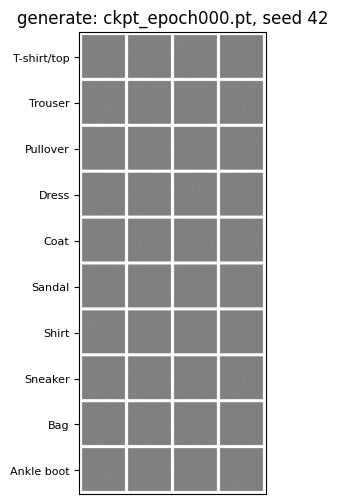

Grid disimpan di: /tmp/tmpr3k73fv5/all.png
Contoh: classifier menilai G BELUM DILATIH (angka rendah itu wajar)
kelas                 n   akurasi
---------------------------------
0: T-shirt/top        4     0.00%
1: Trouser            4     0.00%
2: Pullover           4     0.00%
3: Dress              4     0.00%
4: Coat               4     0.00%
5: Sandal             4     0.00%
6: Shirt              4     0.00%
7: Sneaker            4     0.00%
8: Bag                4   100.00%
9: Ankle boot         4     0.00%
---------------------------------
total (micro)        40    10.00%
rata-rata kelas            10.00%
TES 4b LULUS


In [30]:
OUT_TOL = 1e-4        # selisih float32: forward per-potongan vs satu batch, dan G sumber di CPU vs G di GPU
GRID_PAD = 2          # padding save_image_grid (Bagian 1)
img_shape = (CFG.img_channels, CFG.img_size, CFG.img_size)

with tempfile.TemporaryDirectory() as tmp:
    # --- Persiapan: checkpoint sementara dari G belum dilatih, D dan optimizer dummy ---
    set_seed(CFG.seed)
    G_src = Generator()
    # Isi running stats BatchNorm dengan beberapa forward mode train: tanpa ini G baru di mode eval
    # menghasilkan gambar hampir konstan (Tes 2.5), sehingga tes "seed berbeda -> output berbeda" lemah.
    with torch.no_grad():
        G_src.train()
        for _ in range(3):
            G_src(torch.randn(CFG.batch_size, CFG.z_dim),
                  torch.randint(0, CFG.num_classes, (CFG.batch_size,)))
    G_src.eval()
    D_dummy = nn.Linear(1, 1)                                  # Bagian 5 belum ada; save_checkpoint butuh D
    opt_G = torch.optim.Adam(G_src.parameters(), lr=CFG.lr_g, betas=(CFG.beta1, CFG.beta2))
    opt_D = torch.optim.Adam(D_dummy.parameters(), lr=CFG.lr_d, betas=(CFG.beta1, CFG.beta2))
    ck = ckpt_path(0, tmp)
    save_checkpoint(ck, 0, G_src, D_dummy, opt_G, opt_D)

    # --- Tes 4b.a: bentuk, tipe, rentang, bebas NaN ---
    n = 6
    out = generate(ck, class_id=7, n=n, seed=CFG.seed)
    assert out.shape == (n, *img_shape), f"keluaran {tuple(out.shape)}, seharusnya {(n, *img_shape)}"
    assert out.dtype == torch.float32 and out.device.type == "cpu"
    assert torch.isfinite(out).all(), "ada NaN/Inf di keluaran generate"
    assert out.min() >= -1.0 and out.max() <= 1.0, f"di luar [-1, 1]: [{out.min():.3f}, {out.max():.3f}]"

    # --- Tes 4b.b: bobot benar-benar dari checkpoint + protokol noise (termasuk pemotongan batch) ---
    n_big = CFG.batch_size + 3                                 # memaksa 2 potongan
    out_big = generate(ck, 3, n_big, seed=123)
    z_ref = torch.randn(n_big, CFG.z_dim, generator=torch.Generator().manual_seed(123))
    with torch.no_grad():
        ref = G_src(z_ref, torch.full((n_big,), 3, dtype=torch.long))
    assert torch.allclose(out_big, ref, atol=OUT_TOL), "generate tidak sama dengan G sumber: bobot/noise/pemotongan salah"

    # --- Tes 4b.c: seed sama -> identik; seed beda -> beda; tanpa seed -> beda tiap panggilan ---
    assert torch.equal(generate(ck, 7, n, seed=CFG.seed), out), "seed sama harus memberi output identik"
    assert not torch.equal(generate(ck, 7, n, seed=CFG.seed + 1), out), "seed berbeda harus memberi output berbeda"
    assert not torch.equal(generate(ck, 7, n), generate(ck, 7, n)), "tanpa seed, dua panggilan harus berbeda"
    # z sama, label berbeda -> gambar berbeda (label benar-benar dipakai)
    assert not torch.equal(generate(ck, 0, n, seed=CFG.seed), out), "label berbeda dengan seed sama harus berbeda"

    # --- Tes 4b.d: tanpa gradien, G beku, RNG global tidak bergeser ---
    assert not out.requires_grad and out.grad_fn is None, "output tidak boleh menyimpan graph gradien"
    G_loaded = load_generator(ck)
    assert not G_loaded.training, "G harus mode eval"
    assert not any(p.requires_grad for p in G_loaded.parameters()), "G hasil load harus beku"
    rng_before = torch.get_rng_state()
    generate(ck, 1, n, seed=5)
    assert torch.equal(torch.get_rng_state(), rng_before), "generate dengan seed tidak boleh menggeser RNG global"

    # --- Tes 4b.e: input tidak sah -> ValueError (dan file tidak ada -> FileNotFoundError) ---
    for kwargs in (dict(class_id=-1, n=4), dict(class_id=CFG.num_classes, n=4), dict(class_id=2.0, n=4),
                   dict(class_id=True, n=4), dict(class_id="3", n=4),
                   dict(class_id=1, n=0), dict(class_id=1, n=-5), dict(class_id=1, n=2.5),
                   dict(class_id=1, n=4, seed=-1), dict(class_id=1, n=4, seed=1.5)):
        try:
            generate(ck, **kwargs)
        except ValueError:
            pass
        else:
            raise AssertionError(f"generate(ck, {kwargs}) seharusnya memunculkan ValueError")
    G_train_mode = load_generator(ck).train()
    try:
        sample_from_generator(G_train_mode, 1, 4)
    except ValueError:
        pass
    else:
        raise AssertionError("G mode train seharusnya ditolak")
    try:
        generate(os.path.join(tmp, "tidak_ada.pt"), 1, 4)
    except FileNotFoundError:
        pass
    else:
        raise AssertionError("checkpoint yang tidak ada seharusnya memunculkan FileNotFoundError")

    # --- Tes 4b.f: config checkpoint berbeda ditolak dengan pesan yang menyebut field-nya ---
    bad = torch.load(ck, map_location="cpu", weights_only=True)
    bad["config"]["g_embed_dim"] = CFG.g_embed_dim * 2
    bad_ck = os.path.join(tmp, "bad.pt")
    torch.save(bad, bad_ck)
    try:
        generate(bad_ck, 1, 4)
    except ValueError as err:
        assert "g_embed_dim" in str(err), f"pesan error harus menyebut g_embed_dim: {err}"
    else:
        raise AssertionError("checkpoint dengan g_embed_dim berbeda seharusnya ditolak")

    # --- Tes 4b.g: generate_all_classes (grid 10 baris, kolom = noise yang sama) ---
    npc = 4
    grid_path = os.path.join(tmp, "all.png")
    imgs_all, labels_all, grid_all = generate_all_classes(ck, n_per_class=npc, seed=CFG.seed, path=grid_path)
    assert imgs_all.shape == (CFG.num_classes * npc, *img_shape), imgs_all.shape
    assert torch.equal(labels_all, torch.arange(CFG.num_classes).repeat_interleave(npc)), "baris ke-c harus kelas c"
    for c in (0, CFG.num_classes - 1):
        assert torch.equal(imgs_all[c * npc:(c + 1) * npc], generate(ck, c, npc, seed=CFG.seed)), \
            f"baris kelas {c} tidak sama dengan generate(ck, {c}, {npc}, seed)"
    w = npc * (CFG.img_size + GRID_PAD) + GRID_PAD
    h = CFG.num_classes * (CFG.img_size + GRID_PAD) + GRID_PAD
    assert os.path.isfile(grid_path) and Image.open(grid_path).size == (w, h), Image.open(grid_path).size
    assert grid_all.shape == (3, h, w)

    # --- Tes 4b.h: hasil generate langsung bisa dinilai classifier pendamping (jembatan ke Bagian 7) ---
    res = evaluate_classifier(clf, [(imgs_all, labels_all)])
    assert (res["n_per_class"] == npc).all(), "setiap kelas harus dinilai dengan npc gambar"
    assert not torch.isnan(res["per_class"]).any() and 0.0 <= res["acc"] <= 1.0
    print_accuracy_table(res, "Contoh: classifier menilai G BELUM DILATIH (angka rendah itu wajar)")

plt.close("all")
print("TES 4b LULUS")